In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Bank Data Set.xlsx to Bank Data Set.xlsx


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [ ]:
df = pd.read_excel("Bank Data Set.xlsx")

print("Dataset shape:", df.shape)

display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (10000, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no



Column names:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']


In [ ]:
print("Missing values:")
print(df.isnull().sum())

print("\nData types:")
print(df.dtypes)

print("\nTarget distribution:")
print(df["y"].value_counts())

Missing values:
age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

Data types:
age                 int64
job                object
marital            object
education          object
default            object
housing            object
loan               object
contact            object
month              object
day_of_week        object
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome           object
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                 

In [ ]:
X = df.drop("y", axis=1)
y = df["y"]

y = y.map({"no": 0, "yes": 1})

print("Features:", X.shape)
print("Target:", y.shape)

Features: (10000, 20)
Target: (10000,)


In [ ]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Categorical features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


In [ ]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 8000
Testing observations: 2000


In [ ]:
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

y_pred_lr = logistic_model.predict(X_test)

In [ ]:
decision_tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ))
])

decision_tree_model.fit(X_train, y_train)

y_pred_dt = decision_tree_model.predict(X_test)

In [ ]:
def evaluate_model(name, y_test, predictions):

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions, zero_division=0)
    recall = recall_score(y_test, predictions, zero_division=0)
    f1 = f1_score(y_test, predictions, zero_division=0)

    print("\n", "="*50)
    print(name)
    print("="*50)

    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1 Score : {f1:.4f}")

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        predictions,
        target_names=["No", "Yes"],
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, predictions))


evaluate_model(
    "Logistic Regression",
    y_test,
    y_pred_lr
)

evaluate_model(
    "Decision Tree",
    y_test,
    y_pred_dt
)


Logistic Regression
Accuracy : 0.9680
Precision: 0.5455
Recall   : 0.2687
F1 Score : 0.3600

Classification Report:
              precision    recall  f1-score   support

          No       0.98      0.99      0.98      1933
         Yes       0.55      0.27      0.36        67

    accuracy                           0.97      2000
   macro avg       0.76      0.63      0.67      2000
weighted avg       0.96      0.97      0.96      2000

Confusion Matrix:
[[1918   15]
 [  49   18]]

Decision Tree
Accuracy : 0.9665
Precision: 0.5000
Recall   : 0.0149
F1 Score : 0.0290

Classification Report:
              precision    recall  f1-score   support

          No       0.97      1.00      0.98      1933
         Yes       0.50      0.01      0.03        67

    accuracy                           0.97      2000
   macro avg       0.73      0.51      0.51      2000
weighted avg       0.95      0.97      0.95      2000

Confusion Matrix:
[[1932    1]
 [  66    1]]


In [ ]:
results = pd.DataFrame({
    "Algorithm": [
        "Logistic Regression",
        "Decision Tree"
    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt)
    ],

    "Precision": [
        precision_score(y_test, y_pred_lr, zero_division=0),
        precision_score(y_test, y_pred_dt, zero_division=0)
    ],

    "Recall": [
        recall_score(y_test, y_pred_lr, zero_division=0),
        recall_score(y_test, y_pred_dt, zero_division=0)
    ],

    "F1 Score": [
        f1_score(y_test, y_pred_lr, zero_division=0),
        f1_score(y_test, y_pred_dt, zero_division=0)
    ]
})

display(results.round(4))

,Algorithm,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9680,0.5455,0.2687,0.360
1,Decision Tree,0.9665,0.5000,0.0149,0.029


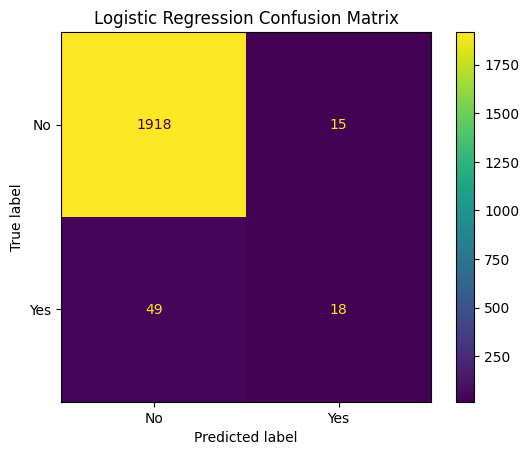

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lr,
    display_labels=["No", "Yes"]
)

plt.title("Logistic Regression Confusion Matrix")
plt.show()

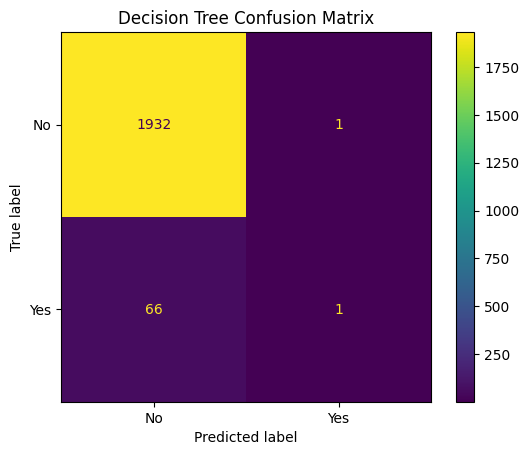

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_dt,
    display_labels=["No", "Yes"]
)

plt.title("Decision Tree Confusion Matrix")
plt.show()

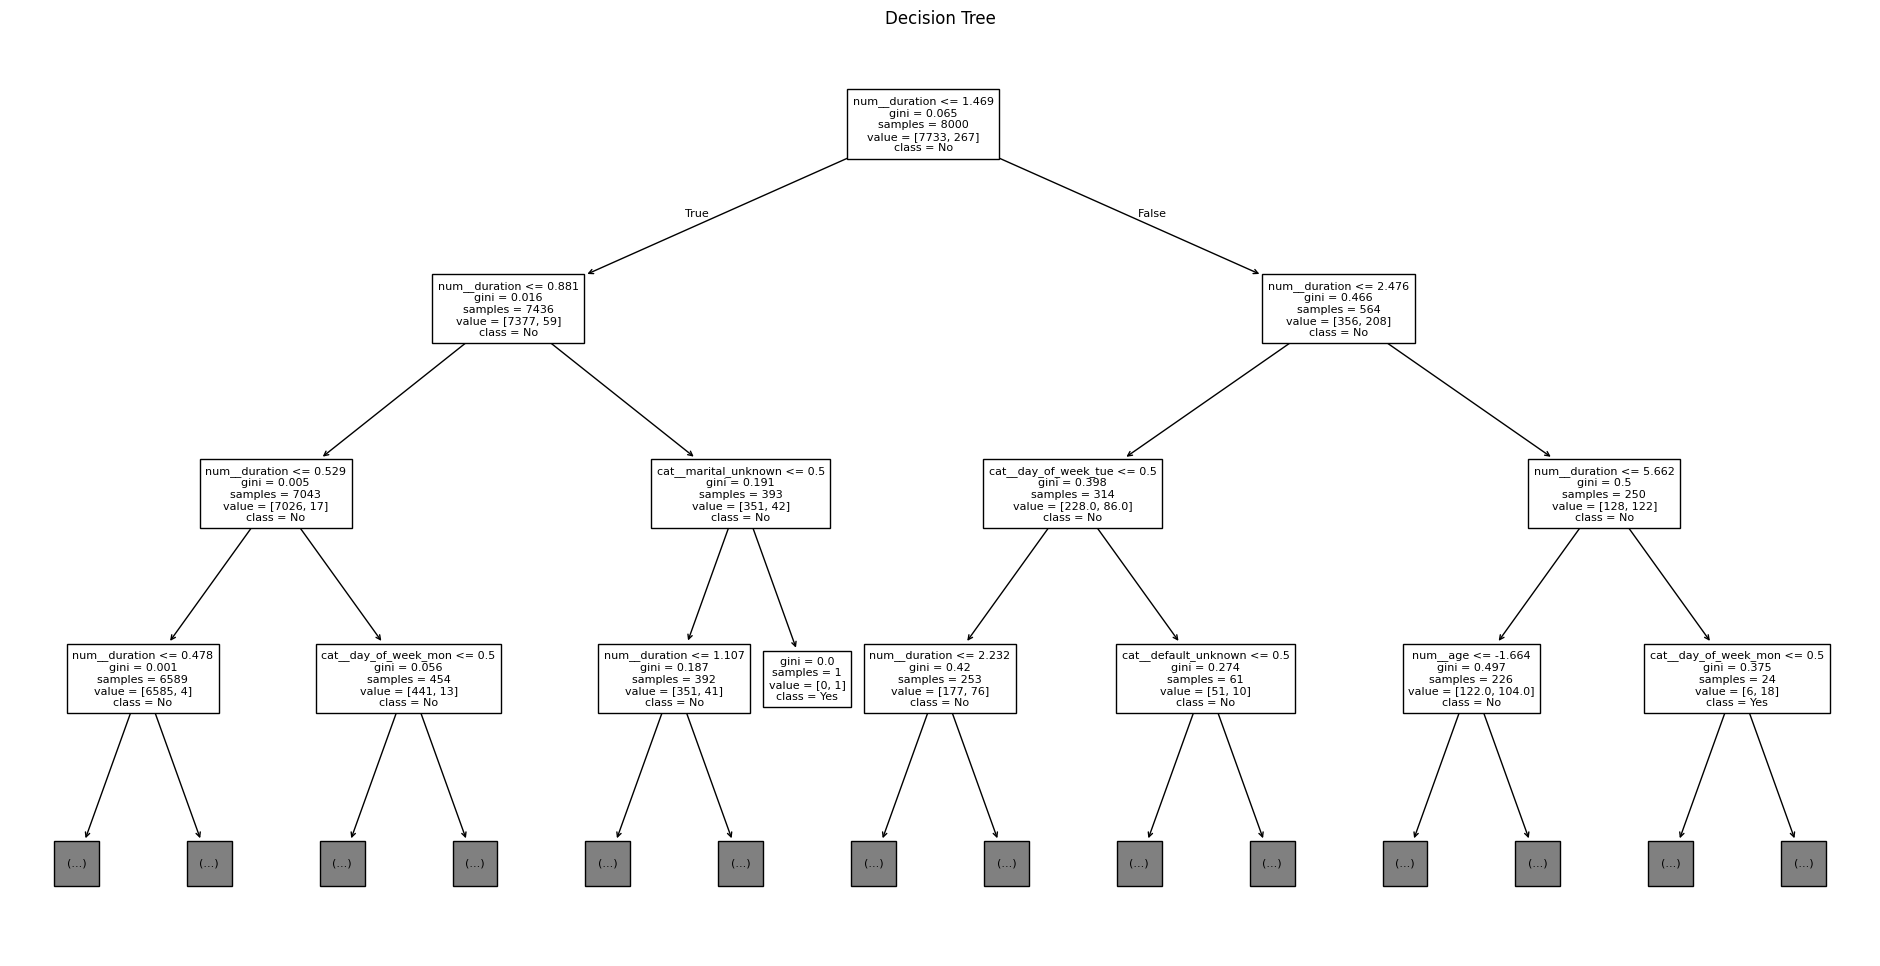

In [ ]:
preprocessor_fitted = decision_tree_model.named_steps["preprocessor"]
tree_classifier = decision_tree_model.named_steps["classifier"]

feature_names = preprocessor_fitted.get_feature_names_out()

plt.figure(figsize=(24, 12))

plot_tree(
    tree_classifier,
    feature_names=feature_names,
    class_names=["No", "Yes"],
    filled=False,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree")
plt.show()